# RFM vs. CellFlow on EB differentiation: the 3-gene and the 3-PC scenario

**Contents.** The four-way comparison of `riemannian_eb_genes_example.ipynb`, run on the two 3-dimensional scenarios of `data/eb_ot_v2.ipynb`:

| Scenario | Coordinates | Selected by |
| --- | --- | --- |
| **3 genes** | RPL12, VIM, COL3A1: log-expression after `normalize_total(1e4)` and `log1p` | greedy kNN time structure among highly variable, time-dependent genes |
| **3 PCs** | PC1, PC2, PC6 of a 50-component PCA fitted on the benchmark's training cells (`data/eb_ot_v2/eb_pca.npz`) | the same greedy selection among the 50 components |

Both scenarios use the same four models, trained from the $t=0$ cells (source) to the $t=1$ cells (target) of the training split:

| | Biharmonic OT coupling | Euclidean OT coupling |
| --- | --- | --- |
| **Riemannian FM** (`solver="otrfm"`) | RFM + biharmonic OT | RFM + Euclidean OT |
| **Euclidean FM** (`solver="otfm"`) | FM + biharmonic OT | **FM + Euclidean OT** = standard CellFlow |

For each scenario, the notebook shows:

1. **The data** as 3-D point clouds coloured by experimental time.
2. **The reference vector fields** for one pair of points $(x_0, x_1)$: the medoids of the training graph points at $t=0$ and $t=1$. These are the conditional target fields that each method regresses onto:
   - Euclidean FM: $u_t(x\mid x_1)=(x_1-x)/(1-t)$, whose integral curve from $x_0$ is the straight line;
   - RFM: $u_t(x\mid x_1)=-\,d(x,x_1)\,\nabla d(x,x_1)/\big(\|\nabla d(x,x_1)\|^2(1-t)\big)$ with the biharmonic distance $d$, integrated by Euler steps.

   Both fields are shown at $t=0$. Their direction does not depend on $t$; only their magnitude scales with $1/(1-t)$.
3. **The learned vector fields** $v_\theta(t,x)$ of all four variants at $t = 0, 0.5, 1$, and the learned trajectories.
4. **The comparison metrics**: endpoints at $t=1$, and the intermediate days $t=0.25, 0.5, 0.75$, on held-out cells.

**Settings.** Everything follows `riemannian_eb_genes_example.ipynb` (split, graph, kernel, network, OT, training), with four exceptions:

- **All cells are kept.** No "expresses all three genes" filter is applied.
- **Only the variable-Gaussian kernel is fitted.** It is the profile that notebook selected.
- **The 3-PC view is not clipped.** PCA scores are signed, so the clip to $x\ge 0$ after each RFM interpolation step is used for the gene view only.
- **The ODE step limit is raised.** Predictions and paths use the predictor's Tsit5 solver and tolerances, but with up to 100,000 adaptive steps instead of 4,096. The RFM fields of the PCA view are stiff near $t=0$. The tables report the steps used.
- **The RFM velocity cap is scaled to the data.** It is 10 × the mean distance between independent $t=0$ and $t=1$ training cells. In the original MDK/RPL12/VIM view this gives about 26, close to its fixed cap of 30. The PCA coordinates span a larger range than log-expression values.

Run from `CellFlow/docs/notebooks`.

In [1]:
# 1 · imports and settings
import os

os.environ.setdefault("TQDM_DISABLE", "1")   # no per-iteration progress bars in the saved notebook
import json
import warnings

import anndata as ad
import diffrax
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import optax
import pandas as pd
import scanpy as sc
from IPython.display import display
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize
from scipy.spatial.distance import cdist
from scipy.stats import spearmanr

from cellflow.ode_solver import RFMInterpolation
from riemannian_toys import cells, comparison, flows, kernels, plotting

warnings.simplefilter("ignore", FutureWarning)

DATA_DIR = "/ictstr01/groups/ml01/workspace/markus.laengst/data/eb_ot_v2"
if not os.path.exists(DATA_DIR):   # the GPU nodes mount the same workspace under /lustre
    DATA_DIR = DATA_DIR.replace("/ictstr01/", "/lustre/", 1)

# as in riemannian_eb_genes_example.ipynb
split_fractions, split_seed = {"train": 0.7, "val": 0.1, "test": 0.2}, 0
graph_max_cells, graph_seed = 4000, 0
kernel_name = "variable Gaussian"
kernel_settings = {"density_k": 24, "delta": 2.0, "n_modes": 32, "laplacian_type": "unnormalized",
                   "spectral_weight_type": "biharmonic"}
ot_epsilon, batch_size, interpolation_steps, num_iterations, seed = 0.05, 64, 32, 1000, 2026
source_time, target_time = 0.0, 1.0
target_key, condition_name = "day_1", "t=1 cells"
max_ode_steps = 100_000        # adaptive Tsit5 steps per cell; diffrax's default 4,096 is too few for the stiffest RFM fields
velocity_cap_factor = 10.0     # RFM speed cap = factor × mean distance between independent t=0 and t=1 training cells

# velocity field: parameters.json["model"], adapted as in riemannian_eb_genes_example.ipynb
architecture = {
    "condition_mode": "deterministic",
    "regularization": 0.0,
    "pooling": "attention_token",
    "pooling_kwargs": {},
    "layers_before_pool": {"transport": [{"layer_type": "mlp", "dims": (512, 512), "dropout_rate": 0.5}]},
    "layers_after_pool": [{"layer_type": "mlp", "dims": (512, 512), "dropout_rate": 0.1}],
    "condition_embedding_dim": 128,
    "cond_output_dropout": 0.3,
    "condition_encoder_kwargs": {},
    "pool_sample_covariates": True,
    "time_freqs": 1024,
    "time_encoder_dims": (512, 512),
    "time_encoder_dropout": 0.1,
    "hidden_dims": (512, 512),
    "hidden_dropout": 0.2,
    "conditioning": "film",
    "decoder_dims": (1024, 1024),
    "vf_act_fn": jax.nn.silu,
    "layer_norm_before_concatenation": False,
    "linear_projection_before_concatenation": False,
}
MODEL_COLORS = {"RFM + biharmonic OT": "tab:green", "RFM + Euclidean OT": "tab:cyan",
                "FM + biharmonic OT": "tab:purple", "FM + Euclidean OT": "tab:pink"}
CELLFLOW = "FM + Euclidean OT"
print("jax devices:", jax.devices())

jax devices: [CudaDevice(id=0)]


## The data in both views

Both views use all 18,203 cells and the same split: 70% train, 10% validation and 20% test within every time point (the RFM notebook's `stratified_group_split`, seed 0).

In [2]:
# 2 · data, the two views, split
adata = ad.read_h5ad(f"{DATA_DIR}/eb_prepared.h5ad")
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)
scen = json.load(open(f"{DATA_DIR}/eb_scenarios.json"))
pz = np.load(f"{DATA_DIR}/eb_pca.npz")
assert (pz["obs_names"] == adata.obs_names.to_numpy(dtype=str)).all()

time = adata.obs["experimental_time"].to_numpy(np.float64)
time_levels = np.unique(time)
S = {
    "3 genes": {"X": cells.gene_view(adata, scen["genes"]["3"]["var_names"]),
                "labels": list(scen["genes"]["3"]["symbols"]), "clip": True, "unit": "log-expression"},
    "3 PCs": {"X": np.ascontiguousarray(pz["scores"][:, scen["pca"]["time_selected"]["3"]["pcs"]], dtype=np.float32),
              "labels": list(scen["pca"]["time_selected"]["3"]["labels"]), "clip": False, "unit": "PC score"},
}
split = cells.stratified_group_split(time, adata.obs["duplicate_group"].astype(str).to_numpy(), split_fractions, split_seed)
display(cells.split_table(split, time))


def cells_at(s, split_name, t):
    return s["X"][(split == split_name) & np.isclose(time, t)]


view_rows = {}
for name, s in S.items():
    X = s["X"]
    lo, hi = np.quantile(X, 0.002, axis=0), np.quantile(X, 0.998, axis=0)
    pad = 0.04 * (hi - lo)
    s["lims"] = list(zip(lo - pad, hi + pad))
    s["extent"] = float((hi - lo).max())
    s["day_means"] = np.vstack([X[np.isclose(time, t)].mean(0) for t in time_levels])
    s["bg_ids"] = np.random.default_rng(0).choice(len(X), 3000, replace=False)
    view_rows[name] = {
        "coordinates": ", ".join(s["labels"]),
        "zero fraction per coordinate": ", ".join(f"{v:.2f}" for v in (X == 0).mean(0)),
        "range per coordinate": ", ".join(f"[{a:.1f}, {b:.1f}]" for a, b in zip(X.min(0), X.max(0))),
        "distinct points": len(cells.unique_points(X)[1]),
    }
display(pd.DataFrame(view_rows).T)

time,0.0,0.25,0.5,0.75,1.0,All
split,,,,,,
train,1859,3062,2555,2711,2555,12742
val,266,437,365,387,365,1820
test,531,875,730,775,730,3641
All,2656,4374,3650,3873,3650,18203


,coordinates,zero fraction per coordinate,range per coordinate,distinct points
3 genes,"RPL12, VIM, COL3A1","0.00, 0.08, 0.63","[0.0, 7.2], [0.0, 7.7], [0.0, 6.6]",17898
3 PCs,"PC1, PC2, PC6","0.00, 0.00, 0.00","[-13.7, 22.4], [-10.2, 16.2], [-13.4, 12.1]",18203


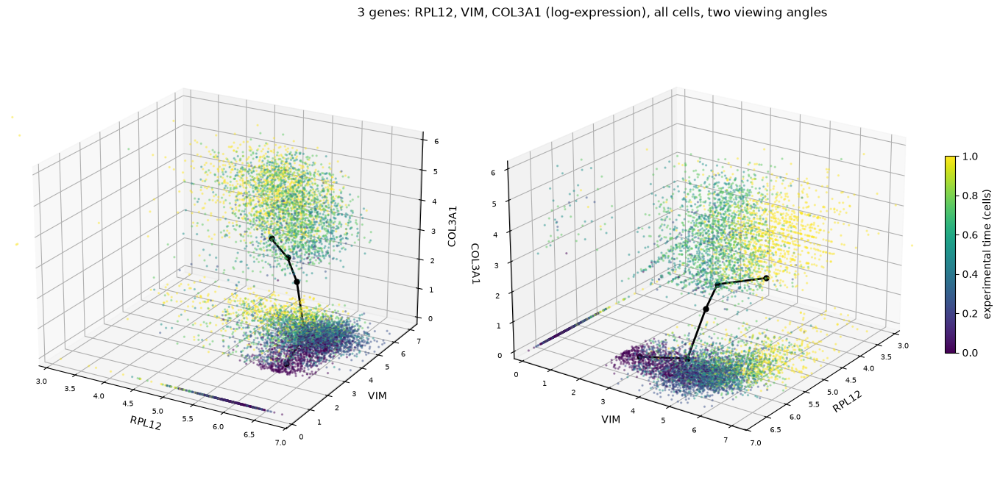

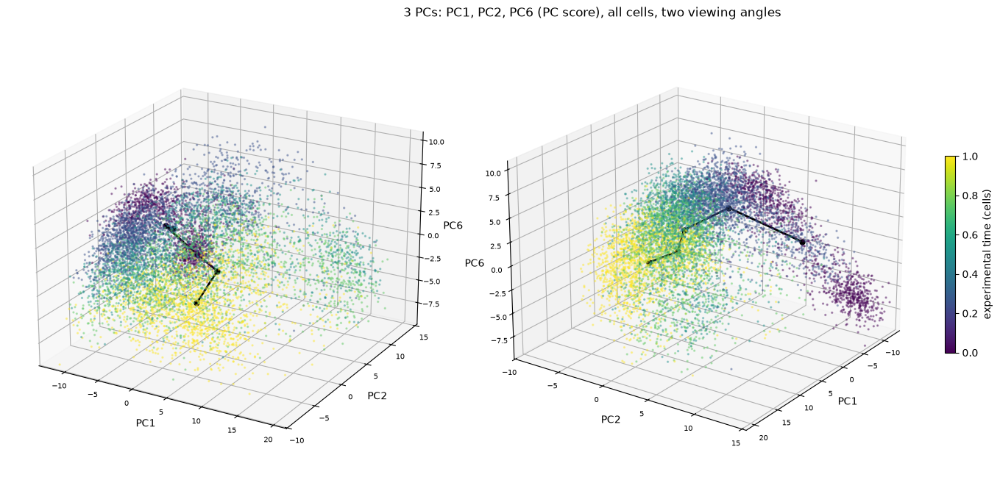

In [3]:
# 3 · 3-D views of the data (subsample of 8,000 cells; black: mean per time point)
TIME_NORM = Normalize(0.0, 1.0)


def setup_axes(ax, s, elev=22, azim=-60):
    ax.set(xlim=s["lims"][0], ylim=s["lims"][1], zlim=s["lims"][2])
    ax.set_xlabel(s["labels"][0], labelpad=-1)
    ax.set_ylabel(s["labels"][1], labelpad=-1)
    ax.set_zlabel(s["labels"][2], labelpad=-1)
    ax.tick_params(labelsize=7, pad=0)
    ax.view_init(elev=elev, azim=azim)


def time_colorbar(fig, axes, label="experimental time (cells)"):
    fig.colorbar(ScalarMappable(TIME_NORM, "viridis"), ax=axes, shrink=0.45, pad=0.02, label=label)


for name, s in S.items():
    ids = np.random.default_rng(1).choice(len(time), 8000, replace=False)
    fig = plt.figure(figsize=(17, 6.6))
    axes = []
    for k, azim in enumerate((-60, 35)):
        ax = fig.add_subplot(1, 2, k + 1, projection="3d")
        ax.scatter(*s["X"][ids].T, c=time[ids], cmap="viridis", norm=TIME_NORM, s=2, alpha=0.35, depthshade=False,
                   rasterized=True)
        ax.plot(*s["day_means"].T, "k-o", ms=5, lw=2)
        setup_axes(ax, s, azim=azim)
        axes.append(ax)
    fig.subplots_adjust(left=0.0, right=0.92, top=0.92, bottom=0.02, wspace=0.0)
    time_colorbar(fig, axes)
    fig.suptitle(f"{name}: {', '.join(s['labels'])} ({s['unit']}), all cells, two viewing angles")
    plt.show()

## Graph and biharmonic geometry

The graph uses 4,000 training cells drawn over all five time points, reduced to their distinct points. Validation and test cells never enter it. The variable-Gaussian CkNN kernel ($k_\rho=24$, $\delta=2$) gives 32 biharmonic modes and a continuous Nyström extension.

`lambda_2`, the smallest non-zero eigenvalue of the graph Laplacian, measures how well connected the graph is: a small value means a bottleneck. The biharmonic coordinate $\Psi_2=\phi_2/\lambda_2$ then dominates every distance.

In [4]:
# 4 · graph, kernel and Nyström extension per view; RFM velocity cap
train_ids = np.flatnonzero(split == "train")
graph_ids = np.sort(np.random.default_rng(graph_seed).choice(train_ids, graph_max_cells, replace=False))
assert set(split[graph_ids]) == {"train"}

geometry_rows = {}
for name, s in S.items():
    points, counts, inverse = cells.unique_points(s["X"][graph_ids])
    point_time = np.bincount(inverse, weights=time[graph_ids]) / counts
    models, fitted, _, fit_df = kernels.fit_kernel_profiles(points, {kernel_name: kernels.KERNEL_PROFILES[kernel_name]},
                                                            **kernel_settings)
    s.update(points=points, point_time=point_time, nystroem=models[kernel_name])
    s["cloud"] = cells.CellCloud(points, fitted[kernel_name])
    s["project"] = cells.CellCloud.project if s["clip"] else None
    src, tgt = cells_at(s, "train", source_time), cells_at(s, "train", target_time)
    rng = np.random.default_rng(0)
    pair_dist = np.linalg.norm(src[rng.integers(len(src), size=5000)] - tgt[rng.integers(len(tgt), size=5000)], axis=1)
    s["velocity_cap"] = float(velocity_cap_factor * pair_dist.mean())
    psi = np.asarray(s["nystroem"].Psi)
    geometry_rows[name] = {
        "distinct graph points": len(points),
        **fit_df.loc[kernel_name, ["edges", "components", "min_degree", "median_degree", "lambda_2"]].to_dict(),
        **{f"|spearman(Psi_{k + 1}, time)|": abs(spearmanr(psi[:, k], point_time)[0]) for k in range(3)},
        **{f"{sp} cells in support": float(s["cloud"].contains(s["X"][split == sp]).mean()) for sp in cells.SPLITS},
        "mean distance t=0 to t=1 cells": float(pair_dist.mean()),
        "RFM velocity cap": s["velocity_cap"],
    }
display(pd.DataFrame(geometry_rows).round(4))

variable Gaussian: fitted in 3.00s
variable Gaussian: fitted in 3.01s


,3 genes,3 PCs
distinct graph points,3985.0000,4000.0000
edges,220866.0000,316342.0000
components,1.0000,1.0000
min_degree,12.4028,40.9157
median_degree,76.6148,121.1006
lambda_2,0.0057,1.6473
"|spearman(Psi_1, time)|",0.3642,0.7639
"|spearman(Psi_2, time)|",0.6952,0.2550
"|spearman(Psi_3, time)|",0.5132,0.5244
train cells in support,1.0000,1.0000


### The variable-Gaussian graphs from four viewing angles

This section has the same layout as section 4c of `riemannian_eb_scenarios_3d_fixed_gaussian.ipynb`, for direct comparison.

- **Nodes** are the distinct graph points: training cells from all five days.
- **Edges:** each node draws its four heaviest edges, shaded by $\log_{10}$ weight on the same scale as there (dark = heavy). On the CkNN support, the variable Gaussian's weights lie between $e^{-1/2}\approx 0.61$ and 1, so every drawn edge is dark.
- **Top row:** nodes coloured by experimental time.
- **Bottom row:** nodes coloured by degree, the sum of their edge weights. In red are the support edges whose fixed-Gaussian weight underflows to zero in float32. These are the edges that keep the gene view connected here and are lost with the fixed Gaussian.
- **Views:** three azimuths at 20° elevation and one near-top view.

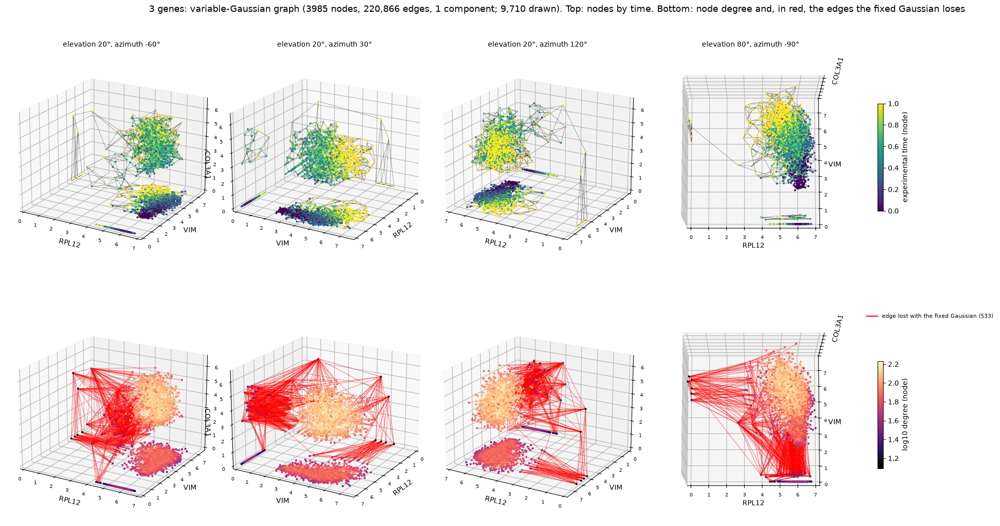

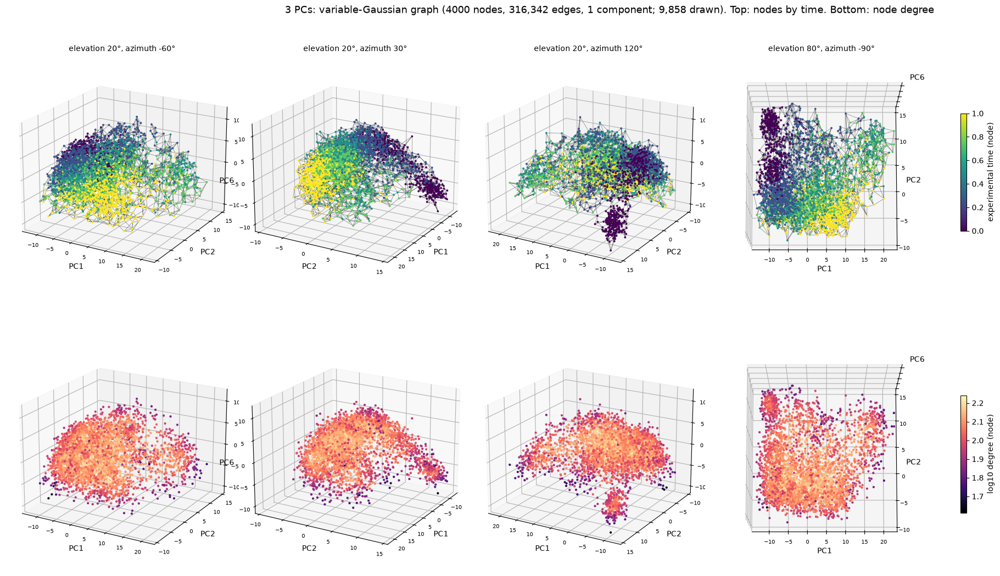

,3 genes,3 PCs
nodes,3985.000000,4000.000000
edges,220866.000000,316342.000000
components,1.000000,1.000000
edges lost with the fixed Gaussian,533.000000,0.000000
min degree,12.402787,40.915737
median degree,76.614822,121.100632
min edge weight,0.606532,0.606533
median edge weight,0.758520,0.739285
drawn edges,9710.000000,9858.000000


In [5]:
# 4c · the variable-Gaussian graph of both views from four viewing angles (layout as in the fixed-Gaussian notebook)
from mpl_toolkits.mplot3d.art3d import Line3DCollection
from scipy.sparse import triu
from scipy.sparse.csgraph import connected_components

from cellflow.preprocessing._kernels import SymmetricBandwidthKernel

VIEW_ANGLES = [(20, -60), (20, 30), (20, 120), (80, -90)]   # (elevation, azimuth)
WEIGHT_NORM = Normalize(-6.0, 0.0, clip=True)                # log10 edge weight, same scale as the fixed-Gaussian notebook
support = {"density_k": kernel_settings["density_k"], "delta": kernel_settings["delta"]}


def strongest_edges(graph, per_node=4):
    # union of every node's per_node heaviest edges, as (i, j, weight) with i < j
    graph = graph.tocsr()
    pairs = []
    for i in range(graph.shape[0]):
        lo, hi = graph.indptr[i], graph.indptr[i + 1]
        top = np.argsort(graph.data[lo:hi])[::-1][:per_node]
        pairs += [(min(i, j), max(i, j)) for j in graph.indices[lo:hi][top]]
    pairs = np.unique(np.asarray(pairs), axis=0)
    return pairs[:, 0], pairs[:, 1], np.asarray(graph[pairs[:, 0], pairs[:, 1]]).ravel()


def add_edges(ax, points, a, b, colors, linewidth=0.4, alpha=0.6):
    ax.add_collection3d(Line3DCollection(np.stack([points[a], points[b]], axis=1), colors=colors,
                                         linewidths=linewidth, alpha=alpha))


def setup_graph_axes(ax, lims, labels, elev, azim):
    ax.set(xlim=lims[0], ylim=lims[1], zlim=lims[2])
    for setter, label in zip((ax.set_xlabel, ax.set_ylabel, ax.set_zlabel), labels):
        setter(label, labelpad=-1)
    ax.tick_params(labelsize=7, pad=0)
    ax.view_init(elev=elev, azim=azim)
    if elev >= 60:                                            # near-top view: the vertical axis is foreshortened
        ax.set_zticklabels([])


graph_rows = {}
for name, s in S.items():
    points, point_time, labels = s["points"], s["point_time"], s["labels"]
    kernel = s["cloud"].kernel                                # the fitted variable-Gaussian kernel
    graph = kernel.graph()
    fixed_graph = SymmetricBandwidthKernel(points, profile="fixed_gaussian", **support).graph()
    lost = triu((graph > 0).astype(np.int8) - (fixed_graph > 0).astype(np.int8), k=1).tocoo()
    lost_a, lost_b = lost.row[lost.data > 0], lost.col[lost.data > 0]
    n_components = connected_components(graph, directed=False)[0]
    degree = np.asarray(graph.sum(axis=1)).ravel()
    a, b, w = strongest_edges(graph)
    edge_colors = plt.get_cmap("Greys")(0.2 + 0.8 * WEIGHT_NORM(np.log10(w)))
    lo, hi = points.min(axis=0), points.max(axis=0)          # every node inside the box (3-D lines are not clipped)
    lims = list(zip(lo - 0.03 * (hi - lo), hi + 0.03 * (hi - lo)))
    graph_rows[name] = {
        "nodes": len(points), "edges": graph.nnz // 2, "components": n_components,
        "edges lost with the fixed Gaussian": len(lost_a),
        "min degree": degree.min(), "median degree": np.median(degree),
        "min edge weight": float(graph.data.min()), "median edge weight": float(np.median(graph.data)),
        "drawn edges": len(a),
    }

    fig = plt.figure(figsize=(22, 11))
    top_axes, bottom_axes = [], []
    degree_norm = Normalize(np.log10(degree).min(), np.log10(degree).max())
    for c, (elev, azim) in enumerate(VIEW_ANGLES):
        ax = fig.add_subplot(2, 4, c + 1, projection="3d")
        add_edges(ax, points, a, b, edge_colors)
        ax.scatter(*points.T, c=point_time, cmap="viridis", norm=TIME_NORM, s=3, depthshade=False)
        setup_graph_axes(ax, lims, labels, elev, azim)
        ax.set_title(f"elevation {elev}°, azimuth {azim}°", fontsize=10)
        top_axes.append(ax)

        ax = fig.add_subplot(2, 4, c + 5, projection="3d")
        add_edges(ax, points, a, b, "lightgrey", alpha=0.3)
        if len(lost_a):
            add_edges(ax, points, lost_a, lost_b, "red", linewidth=0.7, alpha=0.55)
        ax.scatter(*points.T, c=np.log10(degree), cmap="magma", norm=degree_norm, s=4, depthshade=False)
        setup_graph_axes(ax, lims, labels, elev, azim)
        bottom_axes.append(ax)

    fig.subplots_adjust(left=0.0, right=0.93, top=0.92, bottom=0.02, wspace=0.0, hspace=0.08)
    time_colorbar(fig, top_axes, label="experimental time (node)")
    fig.colorbar(ScalarMappable(degree_norm, "magma"), ax=bottom_axes, shrink=0.45, pad=0.02, label="log10 degree (node)")
    if len(lost_a):
        bottom_axes[-1].legend(handles=[plt.Line2D([], [], color="red", label=f"edge lost with the fixed Gaussian ({len(lost_a)})")],
                               loc="upper left", bbox_to_anchor=(1.02, 1.0), fontsize=8, frameon=False)
    fig.suptitle(f"{name}: variable-Gaussian graph ({len(points)} nodes, {graph.nnz // 2:,} edges, {n_components} component; "
                 f"{len(a):,} drawn). Top: nodes by time. Bottom: node degree"
                 + (" and, in red, the edges the fixed Gaussian loses" if len(lost_a) else ""), fontsize=13)
    plt.show()
display(pd.DataFrame(graph_rows))

## Reference vector fields for one pair of points

The pair consists of the medoids of the distinct training graph points at $t=0$ ($x_0$, blue circle) and at $t=1$ ($x_1$, red star). Both reference fields are evaluated at the same 250 graph points, 50 per time point.

- **Arrows** are proportional to the velocity, with one scale per panel: the 90th-percentile speed is drawn as 7% of the plot extent, and longer arrows are shortened to 14%. The panel title gives the median speed, because the two fields differ in magnitude by up to an order of magnitude.
- **Coloured line:** the integral curve from $x_0$. For Euclidean FM it is the straight line; for RFM, 800 Euler steps of the exact field up to $t=0.99$, clipped to $x\ge0$ in the gene view.
- **Third panel:** the same two paths towards $x_1$ from 12 further training points at $t=0$.
- **Backdrop:** the kernel graph of section 4c, translucent, with nodes coloured by time. The grey edges are each node's four heaviest edges plus the minimum spanning tree by edge length. The tree keeps the drawn graph connected like the full graph, so the long edges through sparse regions, which the heaviest edges alone leave out, stay visible. Arrows and paths are drawn on top. The axes cover every graph node and every path.
- **Second figure:** the 13 reference paths over the same graph from the four viewing angles of section 4c. RFM paths are in the top row and straight paths in the bottom row, so you can see where a path runs along the cloud and where it crosses empty space.

,3 genes,3 PCs
x0,"[6.190000057220459, 3.3499999046325684, 0.0]","[-9.050000190734863, 6.46999979019165, 0.07999..."
x1,"[4.929999828338623, 5.699999809265137, 3.17000...","[4.829999923706055, -5.010000228881836, -2.529..."
pair: RFM path length,13.963023,21.852339
pair: straight length,4.101788,18.014076
pair: RFM end error (t=0.99),0.009605,0.002366
13 paths: mean RFM/straight length,2.729469,1.327198
13 paths: mean RFM end error,0.008846,0.007424
RFM paths: max support ratio,0.722997,0.367062
straight paths: max support ratio,15.319013,0.402631
RFM paths: clipped steps,0.029423,NaN


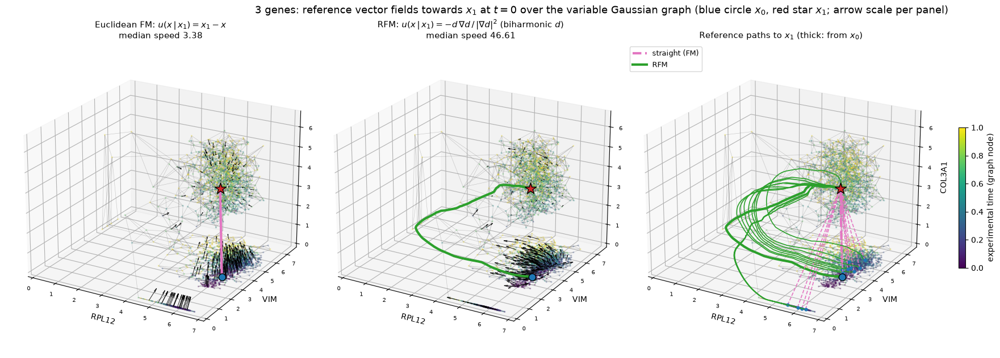

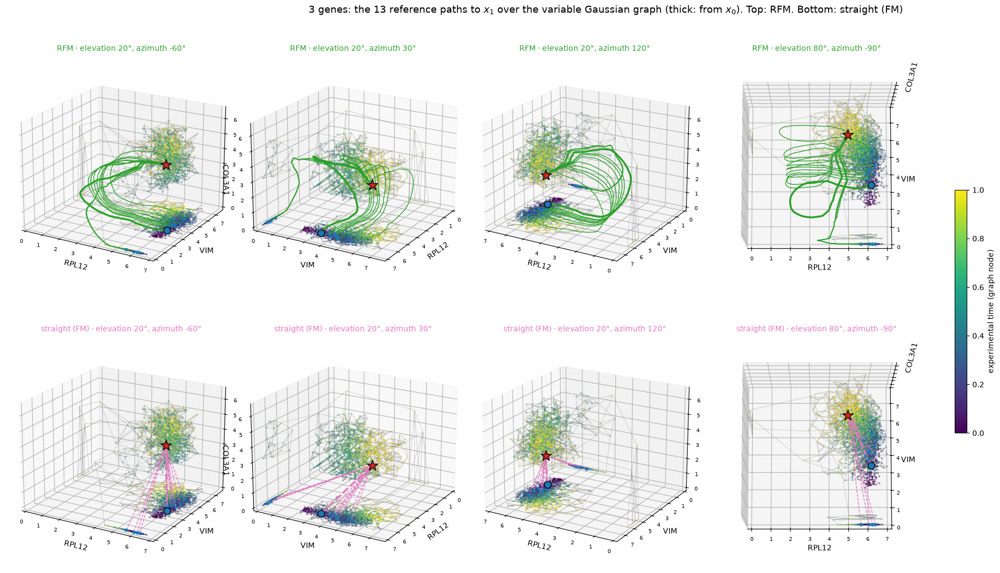

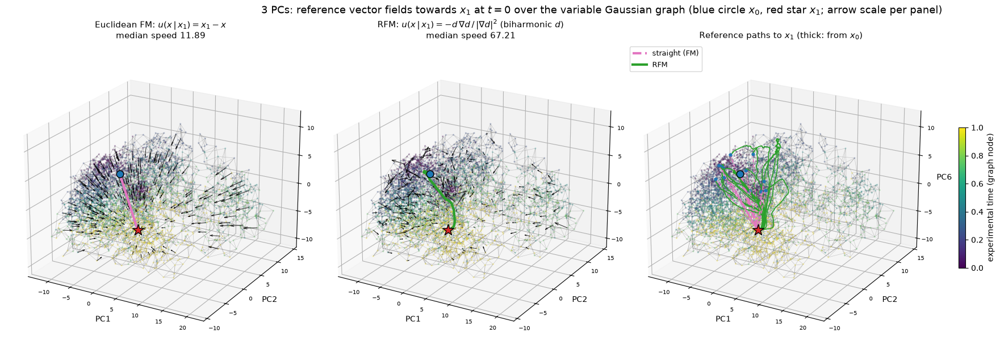

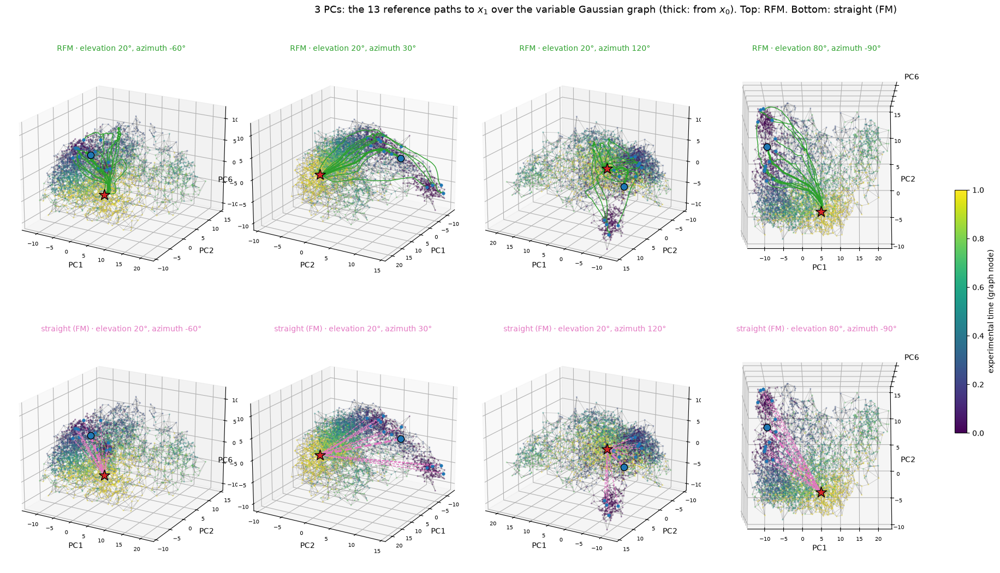

In [6]:
# 5 · the pair, the two reference fields, and their paths
from mpl_toolkits.mplot3d.art3d import Line3DCollection
from scipy.sparse.csgraph import minimum_spanning_tree


def medoid(points):
    return points[cdist(points, points).mean(axis=1).argmin()]


def arrow_scale(fields, extent, frac=0.07):
    # common scale: the 90th-percentile speed is drawn as frac × the plot extent
    speeds = np.concatenate([np.linalg.norm(v, axis=1) for v in fields])
    return frac * extent / max(float(np.quantile(speeds, 0.9)), 1e-12)


def draw_arrows(ax, points, velocities, scale, extent, color="black", max_frac=0.14):
    a = velocities * scale
    length = np.linalg.norm(a, axis=1, keepdims=True)
    a = a * np.minimum(1.0, max_frac * extent / np.maximum(length, 1e-12))
    ax.quiver(*points.T, *a.T, length=1.0, normalize=False, arrow_length_ratio=0.3, color=color, linewidth=0.7,
              alpha=0.85, zorder=3)


def backdrop_edges(s):
    # each node's four heaviest edges (helper from section 4c) plus the minimum spanning tree by edge length:
    # the drawn subgraph is connected like the full graph, so long edges through sparse regions stay visible
    graph = s["cloud"].kernel.graph().tocsr()
    a, b, _ = strongest_edges(graph)
    length = graph.tocoo(copy=True)
    length.data = np.linalg.norm(s["points"][length.row] - s["points"][length.col], axis=1)
    tree = minimum_spanning_tree(length.tocsr()).tocoo()
    pairs = np.unique(np.vstack([np.c_[a, b], np.sort(np.c_[tree.row, tree.col], axis=1)]), axis=0)
    return pairs[:, 0], pairs[:, 1]


def draw_graph(ax, s, edge_alpha=0.35, node_alpha=0.2):
    # translucent backdrop: the backdrop edges (grey) and the graph nodes coloured by time.
    # The axes need computed_zorder=False, so that arrows (zorder 3), paths (4) and markers (5) stay on top.
    a, b = s["graph_edges"]
    ax.add_collection3d(Line3DCollection(np.stack([s["points"][a], s["points"][b]], axis=1), colors="dimgrey",
                                         linewidths=0.45, alpha=edge_alpha, zorder=1, rasterized=True))
    ax.scatter(*s["points"].T, c=s["point_time"], cmap="viridis", norm=TIME_NORM, s=2, alpha=node_alpha,
               depthshade=False, zorder=2, rasterized=True)


def draw_background(ax, s, alpha=0.06):
    ids = s["bg_ids"]
    ax.scatter(*s["X"][ids].T, c=time[ids], cmap="viridis", norm=TIME_NORM, s=2, alpha=alpha, depthshade=False,
               rasterized=True)


def mark_pair(ax, s):
    ax.scatter(*s["x0"], marker="o", s=80, color="tab:blue", edgecolors="black", zorder=5, depthshade=False)
    ax.scatter(*s["x1"], marker="*", s=220, color="tab:red", edgecolors="black", zorder=5, depthshade=False)


reference_rows = {}
for name, s in S.items():
    pts, pt = s["points"], s["point_time"]
    at = {t: pts[np.isclose(pt, t)] for t in time_levels}
    s["x0"], s["x1"] = medoid(at[source_time]), medoid(at[target_time])
    rng = np.random.default_rng(0)
    s["field_points"] = np.vstack([at[t][rng.choice(len(at[t]), 50, replace=False)] for t in time_levels])

    s["interp"] = RFMInterpolation(s["nystroem"], projection_fn=s["project"], max_velocity_norm=s["velocity_cap"])
    F = jnp.asarray(s["field_points"])
    s["u_rfm"] = np.asarray(jax.jit(s["interp"].u_t)(F, jnp.broadcast_to(jnp.asarray(s["x1"]), F.shape), 0.0))
    s["u_fm"] = s["x1"][None, :] - s["field_points"]

    others = at[source_time][np.random.default_rng(seed).choice(len(at[source_time]), 12, replace=False)]
    starts = np.vstack([s["x0"][None, :], others])
    path, proposed = kernels.integrate_euler_paths(s["interp"], starts, s["x1"], 0.99, 800)
    s["ref_times"] = np.linspace(0.0, 0.99, 801)
    s["rfm_paths"] = np.swapaxes(path, 0, 1)                                         # (13, 801, 3)
    s["fm_paths"] = starts[:, None, :] + s["ref_times"][None, :, None] * (s["x1"] - starts)[:, None, :]
    s["graph_edges"] = backdrop_edges(s)
    span = np.vstack([pts, s["rfm_paths"].reshape(-1, pts.shape[1]), s["fm_paths"].reshape(-1, pts.shape[1])])
    lo, hi = span.min(axis=0), span.max(axis=0)                                      # 3-D lines are not clipped
    s["graph_lims"] = list(zip(lo - 0.03 * (hi - lo), hi + 0.03 * (hi - lo)))
    rfm_len = np.linalg.norm(np.diff(s["rfm_paths"], axis=1), axis=-1).sum(axis=1)
    fm_len = np.linalg.norm(np.diff(s["fm_paths"], axis=1), axis=-1).sum(axis=1)
    speed_rfm, speed_fm = np.linalg.norm(s["u_rfm"], axis=1), np.linalg.norm(s["u_fm"], axis=1)
    reference_rows[name] = {
        "x0": np.round(s["x0"], 2).tolist(), "x1": np.round(s["x1"], 2).tolist(),
        "pair: RFM path length": rfm_len[0], "pair: straight length": fm_len[0],
        "pair: RFM end error (t=0.99)": float(np.linalg.norm(s["rfm_paths"][0, -1] - s["x1"])),
        "13 paths: mean RFM/straight length": float(np.mean(rfm_len / fm_len)),
        "13 paths: mean RFM end error": float(np.linalg.norm(s["rfm_paths"][:, -1] - s["x1"], axis=1).mean()),
        "RFM paths: max support ratio": float(s["cloud"].support_ratio(s["rfm_paths"]).max()),
        "straight paths: max support ratio": float(s["cloud"].support_ratio(s["fm_paths"]).max()),
        "RFM paths: clipped steps": float(np.mean(np.any(proposed < 0, axis=-1))) if s["clip"] else np.nan,
        "field: median speed RFM / FM": float(np.median(speed_rfm) / np.median(speed_fm)),
        "field: points at the RFM speed cap": float(np.mean(speed_rfm >= 0.999 * s["velocity_cap"])),
        "field: median cosine(RFM, FM)": float(np.median(np.sum(s["u_rfm"] * s["u_fm"], axis=1)
                                                         / np.maximum(speed_rfm * speed_fm, 1e-12))),
    }
display(pd.DataFrame(reference_rows))

for name, s in S.items():
    fig = plt.figure(figsize=(21, 6.4))
    axes = []
    panels = [(r"Euclidean FM: $u(x\,|\,x_1) = x_1 - x$", s["u_fm"], s["fm_paths"][0], MODEL_COLORS[CELLFLOW]),
              (r"RFM: $u(x\,|\,x_1) = -d\,\nabla d\,/\,|\nabla d|^2$ (biharmonic $d$)", s["u_rfm"], s["rfm_paths"][0],
               MODEL_COLORS["RFM + biharmonic OT"])]
    for k, (title, field, path, color) in enumerate(panels):
        ax = fig.add_subplot(1, 3, k + 1, projection="3d", computed_zorder=False)
        draw_graph(ax, s)
        draw_arrows(ax, s["field_points"], field, arrow_scale([field], s["extent"]), s["extent"])
        ax.plot(*path.T, color=color, lw=3, zorder=4)
        mark_pair(ax, s)
        setup_axes(ax, s)
        ax.set(xlim=s["graph_lims"][0], ylim=s["graph_lims"][1], zlim=s["graph_lims"][2])
        ax.set_title(f"{title}\nmedian speed {np.median(np.linalg.norm(field, axis=1)):.2f}", fontsize=11)
        axes.append(ax)
    ax = fig.add_subplot(1, 3, 3, projection="3d", computed_zorder=False)
    draw_graph(ax, s)
    for i in range(len(s["rfm_paths"])):
        lw = 3 if i == 0 else 1.2
        ax.plot(*s["fm_paths"][i].T, color=MODEL_COLORS[CELLFLOW], lw=lw, ls="--", zorder=4,
                label="straight (FM)" if i == 0 else None)
        ax.plot(*s["rfm_paths"][i].T, color=MODEL_COLORS["RFM + biharmonic OT"], lw=lw, zorder=4,
                label="RFM" if i == 0 else None)
        ax.scatter(*s["rfm_paths"][i, 0], s=12, color="tab:blue", depthshade=False, zorder=4)
    mark_pair(ax, s)
    setup_axes(ax, s)
    ax.set(xlim=s["graph_lims"][0], ylim=s["graph_lims"][1], zlim=s["graph_lims"][2])
    ax.set_title("Reference paths to $x_1$ (thick: from $x_0$)", fontsize=11)
    ax.legend(loc="upper left", fontsize=9)
    axes.append(ax)
    fig.subplots_adjust(left=0.0, right=0.94, top=0.88, bottom=0.02, wspace=0.0)
    time_colorbar(fig, axes, label="experimental time (graph node)")
    fig.suptitle(f"{name}: reference vector fields towards $x_1$ at $t=0$ over the {kernel_name} graph "
                 "(blue circle $x_0$, red star $x_1$; arrow scale per panel)", fontsize=13)
    plt.show()

    # the 13 reference paths over the graph from the four viewing angles of section 4c
    fig = plt.figure(figsize=(22, 11))
    axes = []
    rows = [("RFM", s["rfm_paths"], MODEL_COLORS["RFM + biharmonic OT"], "-"),
            ("straight (FM)", s["fm_paths"], MODEL_COLORS[CELLFLOW], "--")]
    for r, (label, paths, color, ls) in enumerate(rows):
        for c, (elev, azim) in enumerate(VIEW_ANGLES):
            ax = fig.add_subplot(2, 4, 4 * r + c + 1, projection="3d", computed_zorder=False)
            draw_graph(ax, s, edge_alpha=0.45, node_alpha=0.25)
            for i, p in enumerate(paths):
                ax.plot(*p.T, color=color, lw=2.5 if i == 0 else 1.0, ls=ls, zorder=4)
                ax.scatter(*p[0], s=12, color="tab:blue", depthshade=False, zorder=4)
            mark_pair(ax, s)
            setup_graph_axes(ax, s["graph_lims"], s["labels"], elev, azim)              # helper from section 4c
            ax.set_title(f"{label} · elevation {elev}°, azimuth {azim}°", fontsize=10, color=color)
            axes.append(ax)
    fig.subplots_adjust(left=0.0, right=0.93, top=0.92, bottom=0.02, wspace=0.0, hspace=0.08)
    time_colorbar(fig, axes, label="experimental time (graph node)")
    fig.suptitle(f"{name}: the 13 reference paths to $x_1$ over the {kernel_name} graph (thick: from $x_0$). "
                 "Top: RFM. Bottom: straight (FM)", fontsize=13)
    plt.show()

## Training the four variants

The models use the same network, optimizer (Adam, learning rate $10^{-3}$), initialization seed, batch size (64) and number of iterations (1,000). The RFM models interpolate in 32 Euler steps, with the scenario's clip and speed cap. The FM models use the zero-noise straight path. Each coupling is entropic OT with relative $\varepsilon=0.05$, recomputed on every batch: in the Nyström embedding for "biharmonic", on the coordinates for "Euclidean".

===== 3 genes =====
[########################################] | 100% Completed | 101.68 ms
[########################################] | 100% Completed | 101.69 ms
[########################################] | 100% Completed | 100.96 ms
[########################################] | 100% Completed | 101.95 ms
[########################################] | 100% Completed | 100.85 ms
[########################################] | 100% Completed | 101.82 ms
[########################################] | 100% Completed | 100.85 ms
[########################################] | 100% Completed | 101.79 ms
[########################################] | 100% Completed | 100.84 ms
source (1859, 3), target (2555, 3); velocity-field parameters: 4,273,475
Training RFM + biharmonic OT
RFM + biharmonic OT: 50.8s; mean loss first 25 73.48068, last 25 41.87081
Training RFM + Euclidean OT
RFM + Euclidean OT: 25.9s; mean loss first 25 66.04684, last 25 43.34571
Training FM + biharmonic OT
FM + biharmonic OT: 12.0s; 

,training_seconds,mean_loss_first_25,mean_loss_last_25
RFM + biharmonic OT,50.8475,73.4807,41.8708
RFM + Euclidean OT,25.9319,66.0468,43.3457
FM + biharmonic OT,11.9889,3.5406,0.9961
FM + Euclidean OT,10.3746,3.2523,0.6631


[########################################] | 100% Completed | 101.41 ms
[########################################] | 100% Completed | 100.87 ms
===== 3 PCs =====
[########################################] | 100% Completed | 101.58 ms
[########################################] | 100% Completed | 101.08 ms
[########################################] | 100% Completed | 101.64 ms
[########################################] | 100% Completed | 100.82 ms
[########################################] | 100% Completed | 101.64 ms
[########################################] | 100% Completed | 100.80 ms
[########################################] | 100% Completed | 101.73 ms
[########################################] | 100% Completed | 100.83 ms
source (1859, 3), target (2555, 3); velocity-field parameters: 4,273,475
Training RFM + biharmonic OT
RFM + biharmonic OT: 26.9s; mean loss first 25 671.06155, last 25 456.57339
Training RFM + Euclidean OT
RFM + Euclidean OT: 25.6s; mean loss first 25 677.39058,

,training_seconds,mean_loss_first_25,mean_loss_last_25
RFM + biharmonic OT,26.9098,671.0616,456.5734
RFM + Euclidean OT,25.6260,677.3906,437.8338
FM + biharmonic OT,10.5318,33.4339,15.6959
FM + Euclidean OT,10.2476,31.7360,11.2432


[########################################] | 100% Completed | 101.44 ms
[########################################] | 100% Completed | 100.90 ms


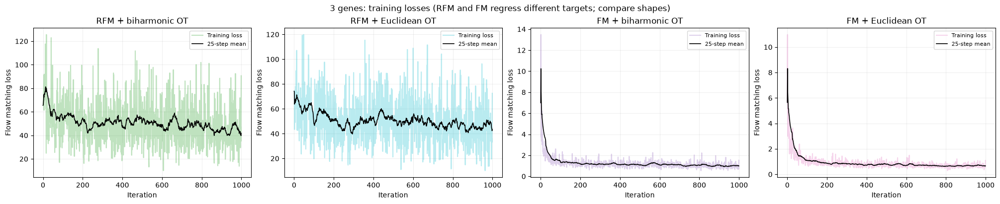

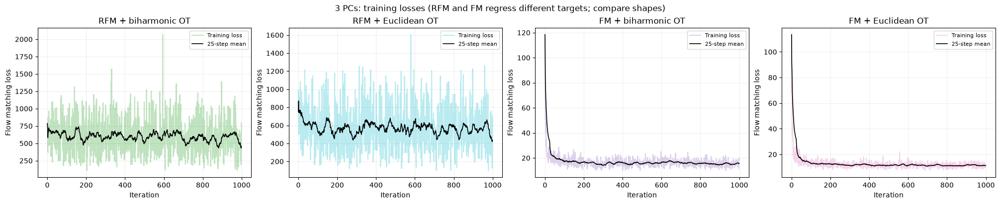

In [7]:
# 6 · train RFM / FM × biharmonic / Euclidean OT per view
def predict(model, starts):
    # solver.predict (Tsit5, PID rtol = atol = 1e-5) with the raised step limit
    _, condition, _ = flows.inference_inputs(model)
    out = np.asarray(model.solver.predict(np.asarray(starts, dtype=np.float32), condition, max_steps=max_ode_steps))
    assert out.shape == np.shape(starts) and np.all(np.isfinite(out))
    return out


def integrate_paths(model, starts, save_times, rtol=1e-5, atol=1e-5):
    # flows.integrate_learned_paths with the raised step limit; returns (paths, adaptive steps per start)
    state, condition, encoder_noise = flows.inference_inputs(model)

    def velocity(t, y, params):
        return state.apply_fn({"params": params}, t, y, condition, encoder_noise, train=False)[0]

    def one(params, y0):
        sol = diffrax.diffeqsolve(diffrax.ODETerm(velocity), diffrax.Tsit5(), t0=0.0, t1=1.0, dt0=None, y0=y0, args=params,
                                  stepsize_controller=diffrax.PIDController(rtol=rtol, atol=atol),
                                  saveat=diffrax.SaveAt(ts=jnp.asarray(save_times)), max_steps=max_ode_steps)
        return sol.ys, sol.stats["num_steps"]

    paths, steps = jax.jit(jax.vmap(one, in_axes=(None, 0)))(state.params, jnp.asarray(starts, dtype=jnp.float32))
    paths = np.asarray(paths)
    assert np.all(np.isfinite(paths))
    np.testing.assert_allclose(paths[:, 0], starts, rtol=1e-6, atol=1e-6)
    np.testing.assert_allclose(paths[:, -1], predict(model, starts), rtol=1e-4, atol=1e-4)
    return paths, np.asarray(steps)


for name, s in S.items():
    print(f"===== {name} =====", flush=True)
    src, tgt = cells_at(s, "train", source_time), cells_at(s, "train", target_time)
    s["train_adata"] = flows.make_toy_adata(src, tgt, target_key)
    embed = jax.jit(jax.vmap(s["nystroem"].extend_point))
    match_biharmonic = flows.make_entropic_match_fn(ot_epsilon, embed=embed)
    match_euclidean = flows.make_entropic_match_fn(ot_epsilon)
    rfm = flows.prepare_toy_model(
        s["train_adata"], "otrfm", target_key, **architecture, match_fn=match_biharmonic, nystroem=s["nystroem"],
        optimizer=optax.adam(1e-3), seed=seed,
        solver_kwargs={"interpolation_steps": interpolation_steps, "projection_fn": s["project"],
                       "project_to_manifold": False, "max_velocity_norm": s["velocity_cap"]},
    )
    s["models"] = {
        "RFM + biharmonic OT": rfm,
        "RFM + Euclidean OT": flows.build_matched_model(rfm, s["train_adata"], "otrfm", match_euclidean, target_key, seed,
                                                        nystroem=s["nystroem"]),
        "FM + biharmonic OT": flows.build_matched_model(rfm, s["train_adata"], "otfm", match_biharmonic, target_key, seed),
        "FM + Euclidean OT": flows.build_matched_model(rfm, s["train_adata"], "otfm", match_euclidean, target_key, seed),
    }
    print(f"source {src.shape}, target {tgt.shape}; velocity-field parameters: "
          f"{sum(p.size for p in jax.tree_util.tree_leaves(rfm.solver.vf_state.params)):,}")
    s["losses"], s["training_seconds"] = {}, {}
    display(comparison.train_untrained(s["models"], s["losses"], s["training_seconds"], num_iterations, batch_size).round(4))
    # predictions from arbitrary starts agree with the public predict API
    public = rfm.predict(s["train_adata"][s["train_adata"].obs[flows.SOURCE_KEY]].copy(),
                         covariate_data=pd.DataFrame({flows.SOURCE_KEY: [True], target_key: [True], "condition": [condition_name]}),
                         condition_id_key="condition", max_steps=max_ode_steps)
    np.testing.assert_allclose(predict(rfm, src), np.asarray(public[condition_name]), rtol=1e-4, atol=1e-4)

for name, s in S.items():
    plotting.plot_loss_panels(s["losses"], MODEL_COLORS, f"{name}: training losses (RFM and FM regress different targets; compare shapes)")

## Learned vector fields

$v_\theta(t, x)$ of each variant (inference weights, no dropout), at $t=0, 0.5, 1$, on the same 250 graph points as the reference fields. As above, the arrows show directions with one scale per panel. The magnitudes are in the panel titles and the table: the RFM fields are much faster near $t=0$ than later.

The learned field is a *marginal* field: it averages the conditional fields of all coupled pairs, so it is not expected to point at the one $x_1$ marked here. The table compares the variants with each other: the median cosine similarity with the CellFlow field (FM + Euclidean OT) at the same point and time, and the median speed.

3 genes:


median speed                \
                             0.0    0.5    1.0   
FM + Euclidean OT          2.131  1.594  1.192   
FM + biharmonic OT         1.463  2.028  1.952   
RFM + Euclidean OT        16.272  1.052  1.491   
RFM + biharmonic OT        8.890  0.887  0.840   

                    median cosine with CellFlow field                
                                                  0.0    0.5    1.0  
FM + Euclidean OT                               1.000  1.000  1.000  
FM + biharmonic OT                              0.927  0.990  0.993  
RFM + Euclidean OT                              0.567  0.844  0.663  
RFM + biharmonic OT                             0.562  0.656  0.514

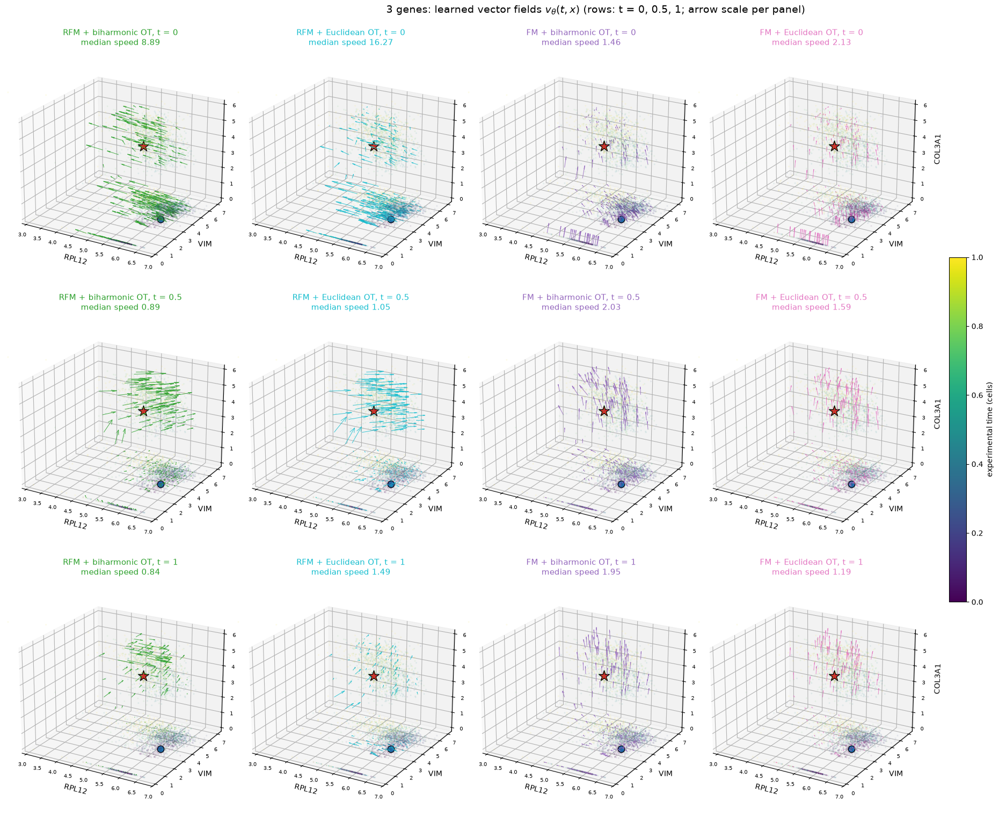

3 PCs:


median speed                  \
                             0.0     0.5     1.0   
FM + Euclidean OT         12.697  14.076  10.787   
FM + biharmonic OT        13.068  11.180  11.017   
RFM + Euclidean OT        34.223   4.928   8.410   
RFM + biharmonic OT       30.487   5.546   5.267   

                    median cosine with CellFlow field                
                                                  0.0    0.5    1.0  
FM + Euclidean OT                               1.000  1.000  1.000  
FM + biharmonic OT                              0.984  0.970  0.983  
RFM + Euclidean OT                              0.949  0.694  0.361  
RFM + biharmonic OT                             0.908  0.733  0.462

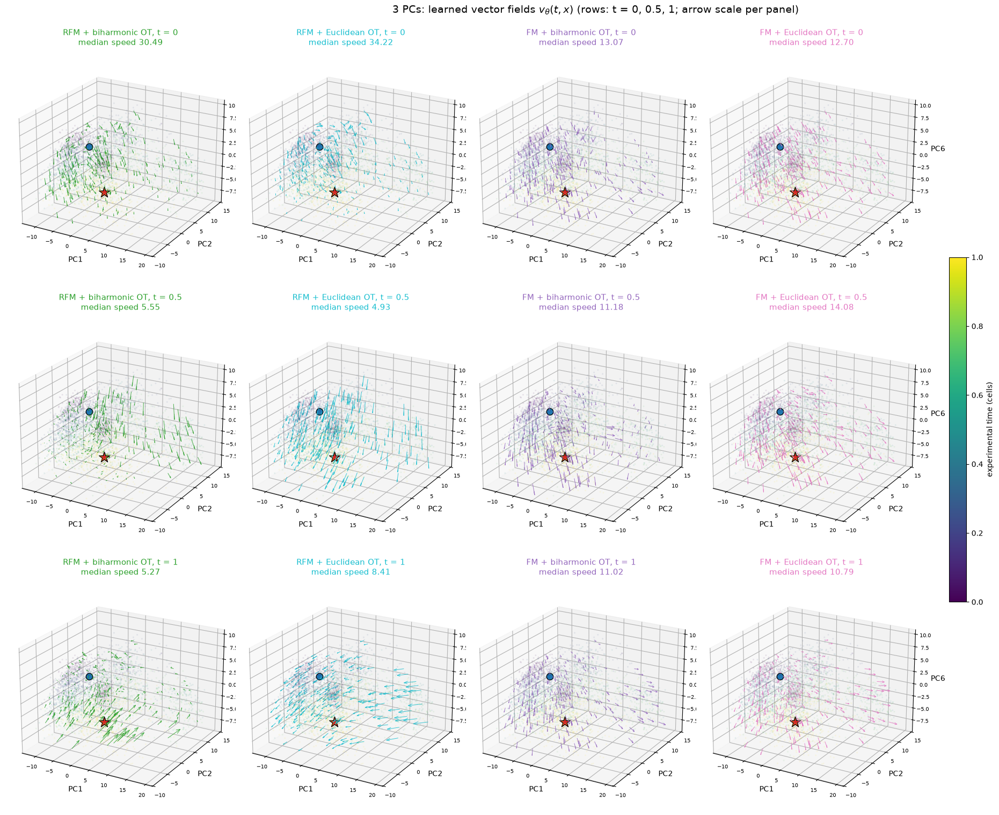

In [8]:
# 7 · learned fields at t = 0, 0.5, 1
field_times = (0.0, 0.5, 1.0)
for name, s in S.items():
    s["learned"] = {(m, t): flows.evaluate_learned_field(model, s["field_points"], t)
                    for m, model in s["models"].items() for t in field_times}
    rows = {}
    for (m, t), v in s["learned"].items():
        ref = s["learned"][CELLFLOW, t]
        cos = np.sum(v * ref, axis=1) / np.maximum(np.linalg.norm(v, axis=1) * np.linalg.norm(ref, axis=1), 1e-12)
        rows[(m, t)] = {"median speed": float(np.median(np.linalg.norm(v, axis=1))),
                        "median cosine with CellFlow field": float(np.median(cos))}
    print(f"{name}:")
    display(pd.DataFrame(rows).T.unstack(1).round(3))

    fig = plt.figure(figsize=(22, 15.5))
    axes = []
    for r, t in enumerate(field_times):
        for c, (m, model) in enumerate(s["models"].items()):
            ax = fig.add_subplot(len(field_times), 4, r * 4 + c + 1, projection="3d")
            draw_background(ax, s)
            v = s["learned"][m, t]
            draw_arrows(ax, s["field_points"], v, arrow_scale([v], s["extent"]), s["extent"], color=MODEL_COLORS[m])
            mark_pair(ax, s)
            setup_axes(ax, s)
            ax.set_title(f"{m}, t = {t:g}\nmedian speed {np.median(np.linalg.norm(v, axis=1)):.2f}", fontsize=11,
                         color=MODEL_COLORS[m])
            axes.append(ax)
    fig.subplots_adjust(left=0.0, right=0.94, top=0.93, bottom=0.01, wspace=0.0, hspace=0.12)
    time_colorbar(fig, axes)
    fig.suptitle(f"{name}: learned vector fields $v_\\theta(t, x)$ (rows: t = 0, 0.5, 1; arrow scale per panel)", fontsize=14)
    plt.show()

## Learned trajectories

Each variant's field is integrated from $x_0$ (thick line) and from 8 held-out test cells at $t=0$, with the predictor's Tsit5 settings and 101 saved times, without clipping. Dashed and dotted black lines show the reference RFM path and the straight path from $x_0$ to $x_1$. The backdrop is the same translucent kernel graph as in the reference-field figures, so you can see where the learned paths follow the cloud.

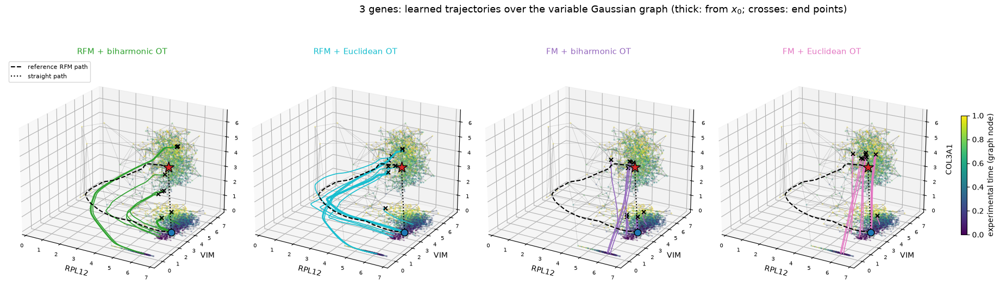

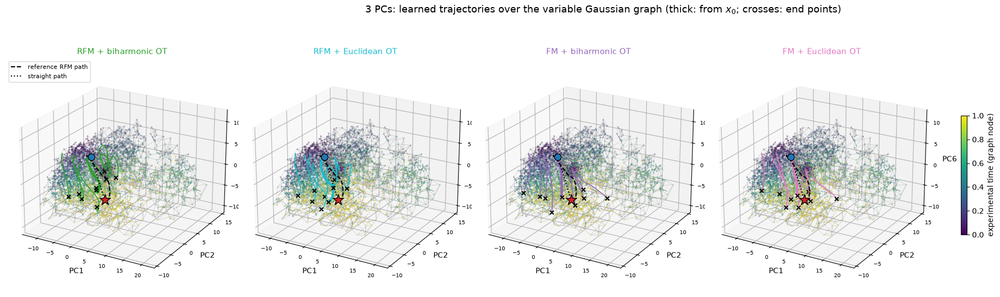

mean_path_length  paths_leaving_support  \
view    model                                                          
3 genes RFM + biharmonic OT            7.7617                 0.0000   
        RFM + Euclidean OT            11.8869                 0.0000   
        FM + biharmonic OT             4.0900                 0.4444   
        FM + Euclidean OT              5.1024                 0.7778   
3 PCs   RFM + biharmonic OT           18.9102                 0.0000   
        RFM + Euclidean OT            16.5414                 0.0000   
        FM + biharmonic OT            15.9092                 0.0000   
        FM + Euclidean OT             16.6060                 0.0000   

                             fraction_saved_points_supported  \
view    model                                                  
3 genes RFM + biharmonic OT                           1.0000   
        RFM + Euclidean OT                            1.0000   
        FM + biharmonic OT                            0.8757   
        FM + Euclidean OT                             0.8185   
3 PCs   RFM + biharmonic OT                           1.0000   
        RFM + Euclidean OT                            1.0000   
        FM + biharmonic OT                            1.0000   
        FM + Euclidean OT                             1.0000   

                             max_support_ratio  median_distance_to_graph  \
view    model                                                              
3 genes RFM + biharmonic OT             0.7657                    0.4110   
        RFM + Euclidean OT              0.6986                    0.5030   
        FM + biharmonic OT             21.7400                    0.1080   
        FM + Euclidean OT              15.3640                    0.2660   
3 PCs   RFM + biharmonic OT             0.3108                    0.5457   
        RFM + Euclidean OT              0.3318                    0.5797   
        FM + biharmonic OT              0.4522                    0.6851   
        FM + Euclidean OT               0.4673                    0.6400   

                             x0 path: end distance to x1  adaptive steps (max)  
view    model                                                                   
3 genes RFM + biharmonic OT                       3.1946                 879.0  
        RFM + Euclidean OT                        0.8868                 873.0  
        FM + biharmonic OT                        3.1707                 549.0  
        FM + Euclidean OT                         0.9200                 511.0  
3 PCs   RFM + biharmonic OT                       4.5606                1307.0  
        RFM + Euclidean OT                        3.9515                1413.0  
        FM + biharmonic OT                        4.8199                 733.0  
        FM + Euclidean OT                         2.3746                 790.0

In [9]:
# 8 · learned paths from x0 and eight test cells
path_times = np.linspace(0.0, 1.0, 101, dtype=np.float32)
path_rows = {}
for name, s in S.items():
    candidates = cells.unique_points(cells_at(s, "test", source_time))[0]
    starts = np.vstack([s["x0"][None, :], candidates[np.random.default_rng(2027).choice(len(candidates), 8, replace=False)]])
    s["learned_paths"], path_steps = {}, {}
    for m, model in s["models"].items():
        s["learned_paths"][m], path_steps[m] = integrate_paths(model, starts, path_times)
    for m, paths in s["learned_paths"].items():
        path_rows[(name, m)] = {**cells.path_metrics(s["cloud"], paths),
                                "x0 path: end distance to x1": float(np.linalg.norm(paths[0, -1] - s["x1"])),
                                "adaptive steps (max)": int(path_steps[m].max())}
    learned = np.concatenate([p.reshape(-1, p.shape[-1]) for p in s["learned_paths"].values()])
    lo = np.minimum([l for l, _ in s["graph_lims"]], learned.min(axis=0))     # every node and path inside the box
    hi = np.maximum([h for _, h in s["graph_lims"]], learned.max(axis=0))
    fig = plt.figure(figsize=(22, 5.8))
    axes = []
    for c, (m, paths) in enumerate(s["learned_paths"].items()):
        ax = fig.add_subplot(1, 4, c + 1, projection="3d", computed_zorder=False)
        draw_graph(ax, s)                                                       # translucent kernel graph (section 5)
        for i, p in enumerate(paths):
            ax.plot(*p.T, color=MODEL_COLORS[m], lw=3 if i == 0 else 1.2, zorder=4)
            ax.scatter(*p[-1], marker="x", s=25, color="black", depthshade=False, zorder=4)
        ax.plot(*s["rfm_paths"][0].T, color="black", lw=1.5, ls="--", zorder=4, label="reference RFM path")
        ax.plot(*s["fm_paths"][0].T, color="black", lw=1.5, ls=":", zorder=4, label="straight path")
        mark_pair(ax, s)
        setup_axes(ax, s)
        ax.set(xlim=(lo[0], hi[0]), ylim=(lo[1], hi[1]), zlim=(lo[2], hi[2]))
        ax.set_title(m, fontsize=11, color=MODEL_COLORS[m])
        axes.append(ax)
    axes[0].legend(loc="upper left", fontsize=8)
    fig.subplots_adjust(left=0.0, right=0.94, top=0.86, bottom=0.02, wspace=0.0)
    time_colorbar(fig, axes, label="experimental time (graph node)")
    fig.suptitle(f"{name}: learned trajectories over the {kernel_name} graph (thick: from $x_0$; crosses: end points)",
                 fontsize=13)
    plt.show()

path_table = pd.DataFrame(path_rows).T.rename_axis(["view", "model"])
display(path_table.drop(columns=["paths_with_negative_expression"]).round(4))

## Comparison on held-out cells

**Endpoints.** The $t=0$ cells of a split are pushed through each learned field and compared with the same split's $t=1$ cells:

- squared energy distance;
- empirical $W_2$ (exact assignment on subsamples of at most 1,500 cells);
- the error of the mean;
- support diagnostics.

Two references bracket the models: the unchanged source and the training $t=1$ cells (the finite-sample floor).

**Intermediate days.** The validation $t=0$ cells are integrated to $t=0.25, 0.5, 0.75$ and compared with the validation cells observed on those days. Model time is not tied to experimental time, so this asks more than the models were trained for.

In [10]:
# 9 · endpoint and intermediate metrics
drop = {"3 genes": [], "3 PCs": ["negative_expression_fraction"]}   # sign is meaningless for PCA scores
endpoint_tables, intermediate_tables = {}, {}
inter_times = np.array([0.0, 0.25, 0.5, 0.75, 1.0], dtype=np.float32)
for name, s in S.items():
    s["predicted"], tables = {}, {}
    for split_name in ("val", "test"):
        source, target = cells_at(s, split_name, source_time), cells_at(s, split_name, target_time)
        preds = {m: predict(model, source) for m, model in s["models"].items()}
        s["predicted"][split_name] = preds
        tables[split_name] = cells.metric_table({"unchanged source": source, "training t=1 cells (floor)": cells_at(s, "train", target_time),
                                                 **preds}, target, s["cloud"])
    endpoint_tables[name] = pd.concat(tables, names=["split", "cloud"]).drop(columns=drop[name])

    source = cells_at(s, "val", source_time)
    states, s["val_steps"] = {}, {}
    for m, model in s["models"].items():
        states[m], s["val_steps"][m] = integrate_paths(model, source, inter_times)
    rows = []
    for k, t in enumerate(inter_times[1:-1], start=1):
        clouds = {"unchanged source": source, "training cells of the day (floor)": cells_at(s, "train", t),
                  **{m: states[m][:, k] for m in states}}
        rows.append(cells.metric_table(clouds, cells_at(s, "val", t), s["cloud"]).assign(time=float(t)).rename_axis("cloud").reset_index())
    intermediate_tables[name] = pd.concat(rows).set_index(["time", "cloud"]).drop(columns=drop[name])

for name in S:
    print(f"===== {name}: endpoints at t=1 =====")
    display(endpoint_tables[name].round(4))
    print(f"===== {name}: intermediate days (val) =====")
    display(intermediate_tables[name][["energy_distance_squared", "wasserstein_2", "mean_error_to_target", "unsupported_fraction"]].round(4))

===== 3 genes: endpoints at t=1 =====


energy_distance_squared  wasserstein_2  \
split cloud                                                                
val   unchanged source                             4.2227         4.5408   
      training t=1 cells (floor)                   0.0100         0.7980   
      RFM + biharmonic OT                          0.5498         1.8261   
      RFM + Euclidean OT                           0.4693         1.5108   
      FM + biharmonic OT                           0.8548         2.1991   
      FM + Euclidean OT                            0.1690         1.7122   
test  unchanged source                             4.2814         4.5440   
      training t=1 cells (floor)                   0.0030         0.7589   
      RFM + biharmonic OT                          0.5044         1.7999   
      RFM + Euclidean OT                           0.4596         1.6793   
      FM + biharmonic OT                           0.7215         2.1220   
      FM + Euclidean OT                            0.2167         1.8272   

                                  mean_error_to_target  unsupported_fraction  \
split cloud                                                                    
val   unchanged source                          3.9347                0.0000   
      training t=1 cells (floor)                0.1363                0.0000   
      RFM + biharmonic OT                       1.0390                0.0150   
      RFM + Euclidean OT                        0.9124                0.0000   
      FM + biharmonic OT                        1.4421                0.0000   
      FM + Euclidean OT                         0.3982                0.0000   
test  unchanged source                          3.9653                0.0000   
      training t=1 cells (floor)                0.0604                0.0000   
      RFM + biharmonic OT                       0.9607                0.0188   
      RFM + Euclidean OT                        0.7996                0.0000   
      FM + biharmonic OT                        1.3174                0.0000   
      FM + Euclidean OT                         0.4950                0.0038   

                                  negative_expression_fraction  \
split cloud                                                      
val   unchanged source                                  0.0000   
      training t=1 cells (floor)                        0.0000   
      RFM + biharmonic OT                               0.0000   
      RFM + Euclidean OT                                0.1955   
      FM + biharmonic OT                                0.0677   
      FM + Euclidean OT                                 0.2030   
test  unchanged source                                  0.0000   
      training t=1 cells (floor)                        0.0000   
      RFM + biharmonic OT                               0.0000   
      RFM + Euclidean OT                                0.1563   
      FM + biharmonic OT                                0.0358   
      FM + Euclidean OT                                 0.1827   

                                  median_distance_to_graph  diverged_fraction  
split cloud                                                                    
val   unchanged source                              0.0177                0.0  
      training t=1 cells (floor)                    0.0556                0.0  
      RFM + biharmonic OT                           0.1392                0.0  
      RFM + Euclidean OT                            0.1914                0.0  
      FM + biharmonic OT                            0.0738                0.0  
      FM + Euclidean OT                             0.1101                0.0  
test  unchanged source                              0.0185                0.0  
      training t=1 cells (floor)                    0.0556                0.0  
      RFM + biharmonic OT                           0.1504                0.0  
      RFM + Euclidean OT                   

===== 3 genes: intermediate days (val) =====


energy_distance_squared  \
time cloud                                                        
0.25 unchanged source                                    0.7083   
     training cells of the day (floor)                   0.0033   
     RFM + biharmonic OT                                 1.1279   
     RFM + Euclidean OT                                  3.2555   
     FM + biharmonic OT                                  0.3723   
     FM + Euclidean OT                                   0.5229   
0.50 unchanged source                                    2.1214   
     training cells of the day (floor)                   0.0098   
     RFM + biharmonic OT                                 1.3444   
     RFM + Euclidean OT                                  2.7458   
     FM + biharmonic OT                                  0.9138   
     FM + Euclidean OT                                   0.6175   
0.75 unchanged source                                    3.1590   
     training cells of the day (floor)                   0.0086   
     RFM + biharmonic OT                                 0.5230   
     RFM + Euclidean OT                                  0.7069   
     FM + biharmonic OT                                  1.0895   
     FM + Euclidean OT                                   0.4194   

                                        wasserstein_2  mean_error_to_target  \
time cloud                                                                    
0.25 unchanged source                          2.0766                1.3960   
     training cells of the day (floor)         0.5087                0.0725   
     RFM + biharmonic OT                       2.4364                1.7315   
     RFM + Euclidean OT                        3.7715                3.2025   
     FM + biharmonic OT                        1.5383                0.6541   
     FM + Euclidean OT                         1.6348                0.7705   
0.50 unchanged source                          3.6144                2.6914   
     training cells of the day (floor)         0.5593                0.1522   
     RFM + biharmonic OT                       3.2898                2.0398   
     RFM + Euclidean OT                        3.9980                2.9871   
     FM + biharmonic OT                        2.2966                1.3789   
     FM + Euclidean OT                         2.0830                0.5901   
0.75 unchanged source                          4.0289                3.3106   
     training cells of the day (floor)         0.4480                0.1595   
     RFM + biharmonic OT                       1.7184                1.0309   
     RFM + Euclidean OT                        1.7782                1.2114   
     FM + biharmonic OT                        2.2802                1.6610   
     FM + Euclidean OT                         1.7335                0.5245   

                                        unsupported_fraction  
time cloud                                                    
0.25 unchanged source                                 0.0000  
     training cells of the day (floor)                0.0000  
     RFM + biharmonic OT                              0.0000  
     RFM + Euclidean OT                               0.0000  
     FM + biharmonic OT                               0.2970  
     FM + Euclidean OT                                0.7556  
0.50 unchanged source                                 0.0000  
     training cells of the day (floor)                0.0000  
     RFM + biharmonic OT                              0.0000  
     RFM + Euclidean OT                               0.0000  
     FM + biharmonic OT                               0.0000  
     FM + Euclidean OT                                0.0038  
0.75 unchanged source                                 0.0000  
     training cells of the day (floor)                0.0000  
     RFM + biharmonic OT                              0.0038  
     RFM + Euclidean OT                        

===== 3 PCs: endpoints at t=1 =====


energy_distance_squared  wasserstein_2  \
split cloud                                                                
val   unchanged source                            20.2401        17.8092   
      training t=1 cells (floor)                   0.0298         1.8030   
      RFM + biharmonic OT                          1.0501         3.9445   
      RFM + Euclidean OT                           1.1812         4.2858   
      FM + biharmonic OT                           0.3421         2.7512   
      FM + Euclidean OT                            0.1472         2.8974   
test  unchanged source                            20.7660        18.1136   
      training t=1 cells (floor)                   0.0142         1.4672   
      RFM + biharmonic OT                          1.2363         4.1632   
      RFM + Euclidean OT                           1.4394         4.5356   
      FM + biharmonic OT                           0.4941         2.9834   
      FM + Euclidean OT                            0.2311         2.9157   

                                  mean_error_to_target  unsupported_fraction  \
split cloud                                                                    
val   unchanged source                         16.7849                   0.0   
      training t=1 cells (floor)                0.4603                   0.0   
      RFM + biharmonic OT                       2.5851                   0.0   
      RFM + Euclidean OT                        2.8396                   0.0   
      FM + biharmonic OT                        1.6136                   0.0   
      FM + Euclidean OT                         0.7864                   0.0   
test  unchanged source                         17.1634                   0.0   
      training t=1 cells (floor)                0.3302                   0.0   
      RFM + biharmonic OT                       2.8411                   0.0   
      RFM + Euclidean OT                        3.2067                   0.0   
      FM + biharmonic OT                        2.0013                   0.0   
      FM + Euclidean OT                         1.0854                   0.0   

                                  median_distance_to_graph  diverged_fraction  
split cloud                                                                    
val   unchanged source                              0.5115                0.0  
      training t=1 cells (floor)                    0.4384                0.0  
      RFM + biharmonic OT                           0.4981                0.0  
      RFM + Euclidean OT                            0.5109                0.0  
      FM + biharmonic OT                            0.6047                0.0  
      FM + Euclidean OT                             0.5888                0.0  
test  unchanged source                              0.5136                0.0  
      training t=1 cells (floor)                    0.4384                0.0  
      RFM + biharmonic OT                           0.4902                0.0  
      RFM + Euclidean OT                            0.5365                0.0  
      FM + biharmonic OT                            0.6083                0.0  
      FM + Euclidean OT                             0.5557                0.0

===== 3 PCs: intermediate days (val) =====


energy_distance_squared  \
time cloud                                                        
0.25 unchanged source                                    5.6293   
     training cells of the day (floor)                   0.0233   
     RFM + biharmonic OT                                 3.7483   
     RFM + Euclidean OT                                  3.1033   
     FM + biharmonic OT                                  2.9106   
     FM + Euclidean OT                                   2.7223   
0.50 unchanged source                                   13.1244   
     training cells of the day (floor)                   0.0464   
     RFM + biharmonic OT                                 2.2462   
     RFM + Euclidean OT                                  2.1430   
     FM + biharmonic OT                                  4.1317   
     FM + Euclidean OT                                   3.2885   
0.75 unchanged source                                   15.6533   
     training cells of the day (floor)                   0.0288   
     RFM + biharmonic OT                                 1.7477   
     RFM + Euclidean OT                                  1.9870   
     FM + biharmonic OT                                  2.4035   
     FM + Euclidean OT                                   1.6618   

                                        wasserstein_2  mean_error_to_target  \
time cloud                                                                    
0.25 unchanged source                          9.6773                7.8033   
     training cells of the day (floor)         1.8535                0.3468   
     RFM + biharmonic OT                       6.6596                5.2707   
     RFM + Euclidean OT                        6.0572                4.6214   
     FM + biharmonic OT                        7.1230                4.9174   
     FM + Euclidean OT                         6.8987                4.7973   
0.50 unchanged source                         15.6965               13.3959   
     training cells of the day (floor)         1.9108                0.7803   
     RFM + biharmonic OT                       6.5685                3.5047   
     RFM + Euclidean OT                        6.7436                3.1387   
     FM + biharmonic OT                        8.9706                6.1228   
     FM + Euclidean OT                         8.4313                5.4115   
0.75 unchanged source                         16.8049               15.0051   
     training cells of the day (floor)         2.0294                0.3122   
     RFM + biharmonic OT                       6.1667                3.5354   
     RFM + Euclidean OT                        6.6595                3.7216   
     FM + biharmonic OT                        6.7753                4.6618   
     FM + Euclidean OT                         6.3598                3.4673   

                                        unsupported_fraction  
time cloud                                                    
0.25 unchanged source                                    0.0  
     training cells of the day (floor)                   0.0  
     RFM + biharmonic OT                                 0.0  
     RFM + Euclidean OT                                  0.0  
     FM + biharmonic OT                                  0.0  
     FM + Euclidean OT                                   0.0  
0.50 unchanged source                                    0.0  
     training cells of the day (floor)                   0.0  
     RFM + biharmonic OT                                 0.0  
     RFM + Euclidean OT                                  0.0  
     FM + biharmonic OT                                  0.0  
     FM + Euclidean OT                                   0.0  
0.75 unchanged source                                    0.0  
     training cells of the day (floor)                   0.0  
     RFM + biharmonic OT                                 0.0  
     RFM + Euclidean OT                        

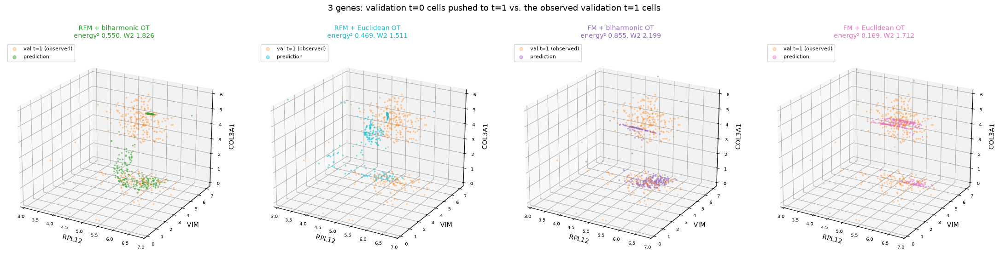

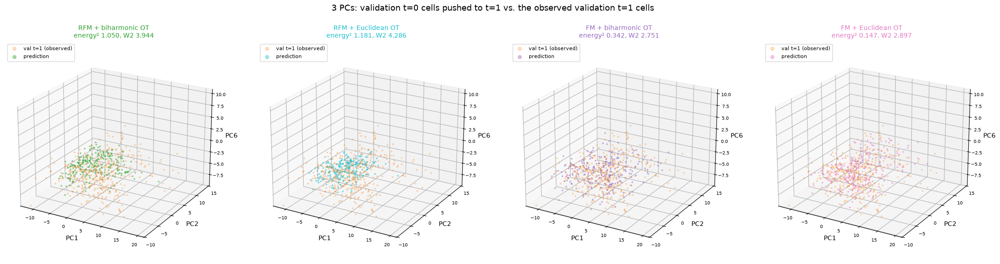

In [11]:
# 10 · predicted t=1 clouds (validation) in 3-D
for name, s in S.items():
    target = cells_at(s, "val", target_time)
    fig = plt.figure(figsize=(22, 5.8))
    for c, (m, pred) in enumerate(s["predicted"]["val"].items()):
        ax = fig.add_subplot(1, 4, c + 1, projection="3d")
        ax.scatter(*target.T, s=3, alpha=0.25, color="tab:orange", depthshade=False, label="val t=1 (observed)")
        ax.scatter(*pred.T, s=3, alpha=0.4, color=MODEL_COLORS[m], depthshade=False, label="prediction")
        setup_axes(ax, s)
        e = endpoint_tables[name].loc[("val", m)]
        ax.set_title(f"{m}\nenergy² {e.energy_distance_squared:.3f}, W2 {e.wasserstein_2:.3f}", fontsize=10, color=MODEL_COLORS[m])
        ax.legend(loc="upper left", fontsize=8, markerscale=3)
    fig.subplots_adjust(left=0.0, right=1.0, top=0.84, bottom=0.02, wspace=0.0)
    fig.suptitle(f"{name}: validation t=0 cells pushed to t=1 vs. the observed validation t=1 cells", fontsize=13)
    plt.show()

In [12]:
# 11 · summary: one row per view and model
summary = {}
for name, s in S.items():
    for m in s["models"]:
        e = endpoint_tables[name]
        inter = intermediate_tables[name].xs(m, level="cloud")
        summary[(name, m)] = {
            "val energy²": e.loc[("val", m), "energy_distance_squared"],
            "test energy²": e.loc[("test", m), "energy_distance_squared"],
            "val W2": e.loc[("val", m), "wasserstein_2"],
            "test W2": e.loc[("test", m), "wasserstein_2"],
            "val mean error": e.loc[("val", m), "mean_error_to_target"],
            "intermediate energy² (mean)": inter["energy_distance_squared"].mean(),
            "intermediate W2 (mean)": inter["wasserstein_2"].mean(),
            "val predictions unsupported": e.loc[("val", m), "unsupported_fraction"],
            "path length": path_table.loc[(name, m), "mean_path_length"],
            "adaptive steps per val cell (median)": float(np.median(s["val_steps"][m])),
            "adaptive steps per val cell (max)": int(s["val_steps"][m].max()),
            "training s": s["training_seconds"][m],
        }
    for ref in ("unchanged source", "training t=1 cells (floor)"):
        e = endpoint_tables[name]
        summary[(name, ref)] = {"val energy²": e.loc[("val", ref), "energy_distance_squared"],
                                "test energy²": e.loc[("test", ref), "energy_distance_squared"],
                                "val W2": e.loc[("val", ref), "wasserstein_2"], "test W2": e.loc[("test", ref), "wasserstein_2"]}
summary_table = pd.DataFrame.from_dict(summary, orient="index").rename_axis(["view", "model"])
display(summary_table.round(4))

val energy²  test energy²   val W2  \
view    model                                                            
3 genes RFM + biharmonic OT              0.5498        0.5044   1.8261   
        RFM + Euclidean OT               0.4693        0.4596   1.5108   
        FM + biharmonic OT               0.8548        0.7215   2.1991   
        FM + Euclidean OT                0.1690        0.2167   1.7122   
        unchanged source                 4.2227        4.2814   4.5408   
        training t=1 cells (floor)       0.0100        0.0030   0.7980   
3 PCs   RFM + biharmonic OT              1.0501        1.2363   3.9445   
        RFM + Euclidean OT               1.1812        1.4394   4.2858   
        FM + biharmonic OT               0.3421        0.4941   2.7512   
        FM + Euclidean OT                0.1472        0.2311   2.8974   
        unchanged source                20.2401       20.7660  17.8092   
        training t=1 cells (floor)       0.0298        0.0142   1.8030   

                                    test W2  val mean error  \
view    model                                                 
3 genes RFM + biharmonic OT          1.7999          1.0390   
        RFM + Euclidean OT           1.6793          0.9124   
        FM + biharmonic OT           2.1220          1.4421   
        FM + Euclidean OT            1.8272          0.3982   
        unchanged source             4.5440             NaN   
        training t=1 cells (floor)   0.7589             NaN   
3 PCs   RFM + biharmonic OT          4.1632          2.5851   
        RFM + Euclidean OT           4.5356          2.8396   
        FM + biharmonic OT           2.9834          1.6136   
        FM + Euclidean OT            2.9157          0.7864   
        unchanged source            18.1136             NaN   
        training t=1 cells (floor)   1.4672             NaN   

                                    intermediate energy² (mean)  \
view    model                                                     
3 genes RFM + biharmonic OT                              0.9984   
        RFM + Euclidean OT                               2.2361   
        FM + biharmonic OT                               0.7919   
        FM + Euclidean OT                                0.5199   
        unchanged source                                    NaN   
        training t=1 cells (floor)                          NaN   
3 PCs   RFM + biharmonic OT                              2.5807   
        RFM + Euclidean OT                               2.4111   
        FM + biharmonic OT                               3.1486   
        FM + Euclidean OT                                2.5575   
        unchanged source                                    NaN   
        training t=1 cells (floor)                          NaN   

                                    intermediate W2 (mean)  \
view    model                                                
3 genes RFM + biharmonic OT                         2.4816   
        RFM + Euclidean OT                          3.1826   
        FM + biharmonic OT                          2.0383   
        FM + Euclidean OT                           1.8171   
        unchanged source                               NaN   
        training t=1 cells (floor)                     NaN   
3 PCs   RFM + biharmonic OT                         6.4649   
        RFM + Euclidean OT                          6.4868   
        FM + biharmonic OT                          7.6230   
        FM + Euclidean OT                           7.2299   
        unchanged source                               NaN   
        training t=1 cells (floor)                     NaN   

                                    val predictions unsupported  path length  \
view    model                                                                  
3 genes RFM + biharmonic OT                               0.015       7.7617   
        RFM + Euclidean OT                                0.000     

## Reading the results

These numbers come from the saved run: one GPU, seed 2026, 1,000 iterations per model. GPU training is not bit-reproducible, so a rerun moves them. In an earlier run, one RFM field of the PCA view was stiff enough to exceed diffrax's default 4,096 solver steps, which is why the step limit is raised.

**Run-to-run noise.** FM + Euclidean OT does not use the kernel, so the PCA-view model has now been trained four times with identical data, seed and batches: twice here and twice in the fixed-Gaussian companion notebook (`riemannian_eb_scenarios_3d_fixed_gaussian.ipynb`). Its validation energy² was 0.10, 0.15, 0.26 and 0.12. Differences of up to about 2.5× between single runs are therefore noise. Only the larger gaps below exceed it, such as RFM against FM at $t=1$ and FM + biharmonic against FM + Euclidean in the gene view.

**3 genes (RPL12, VIM, COL3A1)**

- **Geometry: the graph hangs together through a narrow bridge** ($\lambda_2 = 0.006$, against 1.65 in the PCA view). Most $t=0$ cells lie on the COL3A1 = 0 plane, and cells that express COL3A1 sit at log-expression ≥ 2 above it.
- **Reference fields: RFM detours, FM crosses the gap.**
  - The RFM reference path from $x_0$ to $x_1$ runs through the bridge, at low RPL12 and low VIM. It is 14.0 long against 4.1 for the straight line (2.7× on average over the 13 starts), but it stays inside the kernel support (largest support ratio 0.72).
  - The straight lines cross the empty gap (support ratio up to 15).
  - 60% of the field points are at the RFM speed cap, and the median RFM speed is 14× the FM speed.
- **Learned fields: RFM moves early, FM moves evenly.** The RFM fields have a median speed of 9–16 at $t=0$ and 0.8–1.5 later. The FM fields keep 1.2–2.1 throughout and point mostly along COL3A1.
- **Trajectories: RFM stays supported, FM leaves the support.** The learned RFM paths follow the reference path through the sparse low-RPL12 region: they are 7.8–11.9 long and always supported. FM paths are 4.1–5.1 long and rise straight through the gap; 44–78% of them leave the support at some point.
- **Endpoints (energy², val / test): CellFlow is best.** For reference, doing nothing gives 4.2 and the training $t=1$ cells (the floor) give 0.01.

  | Model | val | test |
  | --- | --- | --- |
  | FM + Euclidean OT (CellFlow) | 0.17 | 0.22 |
  | RFM + Euclidean OT | 0.47 | 0.46 |
  | RFM + biharmonic OT | 0.55 | 0.50 |
  | FM + biharmonic OT | 0.85 | 0.72 |

  The RFM predictions are strung out between the sheet and the COL3A1 cloud (section 10), yet almost all count as supported (1.5–1.9% of the RFM + biharmonic predictions lie outside the support). Prediction is not clipped: 16–20% of the RFM + Euclidean and of the CellFlow predictions have slightly negative expression, against 4–7% for FM + biharmonic and none for RFM + biharmonic.
- **Intermediate days: CellFlow is best on average** (mean energy² 0.52, against 0.79 for FM + biharmonic and 1.00–2.24 for RFM).
  - RFM is worst at $t=0.25$ (1.1–3.3, worse than the unchanged source at 0.71), because it covers most of the distance early.
  - At $t=0.25$, 76% of the CellFlow states lie outside the support, i.e. in the gap.

**3 PCs (PC1, PC2, PC6)**

- **Geometry: well connected** ($\lambda_2 = 1.65$). RFM reference paths are 1.3× the straight length, and all paths stay supported.
- **Endpoints: FM wins.**
  - Energy² (val / test) is 0.15 / 0.23 for FM + Euclidean and 0.34 / 0.49 for FM + biharmonic, against 1.05–1.18 / 1.24–1.44 for RFM.
  - $W_2$ (val) is 2.8–2.9 for FM against 3.9–4.3 for RFM; the floor is 1.5–1.8.
- **Intermediate days: RFM is slightly better in mid-trajectory.** Both RFM variants are best at $t=0.5$ (energy² 2.1–2.2, against 3.3–4.1 for FM) and have the lower mean $W_2$ (6.5, against 7.2–7.6). By mean energy² the variants overlap (2.41–2.58 for RFM, 2.56–3.15 for FM). All models remain far from the floor (0.02–0.05), so none tracks the observed days closely.
- **Learned fields: the same time profile as in the gene view.** RFM is fast at $t=0$ (median speed 30–34) and slower later (5–8). FM stays at 11–14.

**Overall**

- **At $t=1$, CellFlow (FM + Euclidean OT) is best in both views.** The RFM variants are about 3× (genes) and 7–8× (PCs) worse in energy².
- **The geometry helps RFM's paths, not its endpoints.** In the gene view RFM keeps its paths inside the data support, where the straight FM paths cross an empty gap. In the PCA view it fits the middle of the trajectory slightly better.
- **The RFM fields move most cells early.** RFM makes the biharmonic distance to the target fall at a constant rate. The Euclidean speed then depends on how steep that distance is along the path, and it is high near the source in both views.
- **The coupling matters only for FM in the gene view.** There the biharmonic coupling hurts FM (0.85 vs. 0.17). For RFM the two couplings swapped order between runs (0.40 vs. 0.55 in the previous run, 0.55 vs. 0.47 now), so no effect is detectable. In the PCA view the FM gap (0.34 vs. 0.15) is within the run-to-run noise.
- **RFM costs more.** Training takes 2.5–5× as long (26–51 s against 10–12 s on one GPU), and prediction needs about 1.5–2× more adaptive ODE steps.